# 02 Price escalation

**The question.** A price bid in 2019 is not a fair guide to a bid in 2025: highway construction costs rose sharply after 2021. How do we bring every past price to the dollars of the bid being priced, without using anything the estimator could not have known on bid day?

**What we did.** Caltrans publishes a quarterly California highway construction cost index (2020 = 100). Its table sits on a Caltrans site that does not allow automated access, so we did not download it. Instead we recovered it from the cost database pages we had already collected: each page shows every price both *as bid* and *adjusted to today's dollars* with this index, so the ratio gives the index for each quarter. Every contract in a quarter gives the same value, so these are Caltrans' own numbers (decision D-039).

We then adjust prices with the **average of the four quarters published before the bid** (decisions D-040, D-044). The single-quarter index jumps around because each quarter rests on a few contracts, and Caltrans computes a quarter's index from the bids opened in it, so using that quarter's own value would peek at the answer.

**What we found.**
- As bid, typical item prices rose about **44% from 2020 to 2026**. After escalation, yearly price levels stay between **0.83 and 1.24** of 2020, instead of 1.00 to 1.63.
- On 2022 and 2023 training bids, escalation removed the under-pricing that inflation causes in a 12-month historical median: **from about 8% too low to 0.2% too low**.
- Escalation does not track every year. The index follows a broad basket of Caltrans work, and in 2025 these items dipped while the index average was still rising. That gap matters later: models that lean on the index alone drift high (notebook 04).

The full stage report is in [`outputs/09_price_escalation/`](../outputs/09_price_escalation/README.md).

## Setup

This loads the project's own code (`src/bidlens/analysis/stages.py`), which reads the results each stage already saved in `outputs/` (decision D-070). Nothing is recomputed here, so the notebook runs in seconds on a fresh copy of the repository, with no database and no model downloads.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)  # run from the project root

import matplotlib.pyplot as plt
import pandas as pd

from bidlens.analysis import stages as s

pd.set_option("display.max_colwidth", 140)
plt.rcParams["figure.max_open_warning"] = 0

## The cost index, quarter by quarter

The grey line is the published quarterly index; it swings by up to 40% from one quarter to the next. The blue line is the value BidLens uses for a bid opened in that quarter: the mean of the four quarters published before it. It rises from about 94 in 2018 to over 180 in 2025. The last published quarter is 2026 Q1; later quarters carry that value forward (dotted).

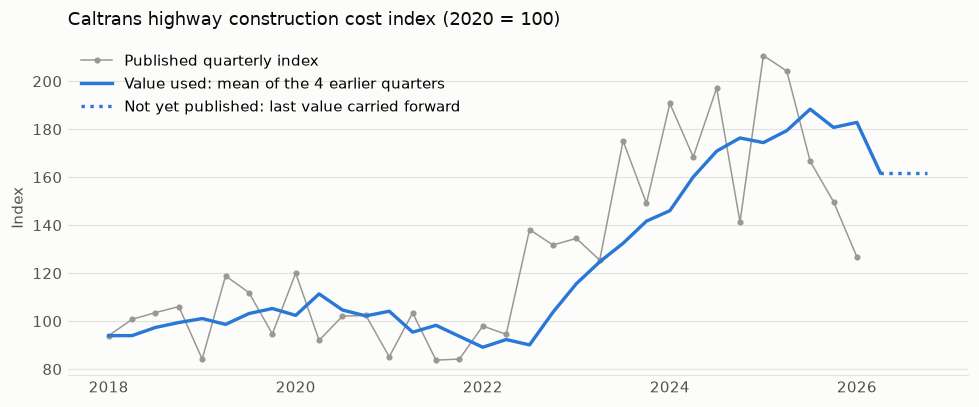

In [2]:
index = s.cost_index()
fig = s.chart_cost_index(index)
s.save(fig, "cost_index", s.S09)
plt.show()

## Do escalated prices stay level?

For each item, its median low-bid price in a year is compared with its own 2020 median, and the table shows the typical ratio across items. If escalation works, the *after escalation* column should stay near 1.00. It is much flatter than the prices as bid, but not perfectly flat: 2022 runs high and 2025 to 2026 run low. The pricing models also see the bid date, so they can correct some of what the index misses.

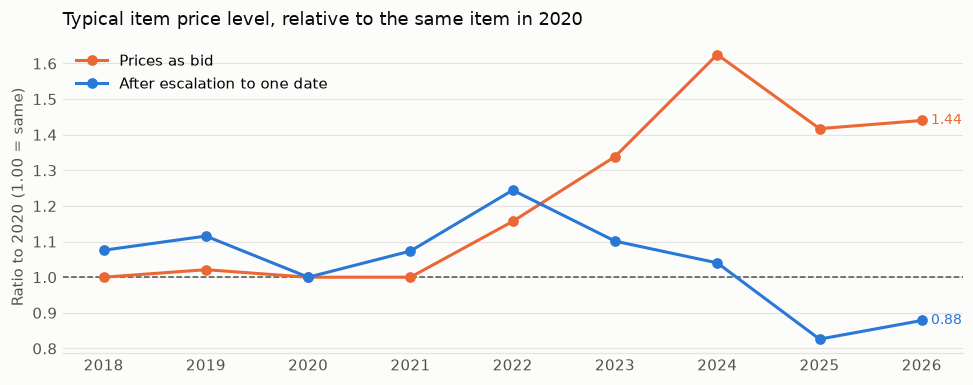

,Bid year,Items,Prices as bid,After escalation
0,2018,76,1.0000,1.0757
1,2019,76,1.0211,1.1155
2,2020,82,1.0000,1.0000
3,2021,81,1.0000,1.0734
4,2022,79,1.1567,1.2444
5,2023,78,1.3385,1.1013
6,2024,74,1.6252,1.0402
7,2025,80,1.4171,0.8261
8,2026,75,1.4400,0.8785


In [3]:
levels = s.price_levels()
fig = s.chart_price_levels(levels)
s.save(fig, "price_levels", s.S09)
plt.show()
levels

## Save and next

This adds the charts above to `outputs/09_price_escalation/` and lists them in its README. To recompute the stage itself: `uv run python -m bidlens.pricing.escalate`.

**Next:** *03 XGBoost baseline*, the first models that price single bid items.

In [4]:
s.note_in_readme(s.S09, "02_price_escalation.ipynb")
sorted(p.name for p in s.S09.glob("nb_*.png"))

['nb_cost_index.png', 'nb_price_levels.png']